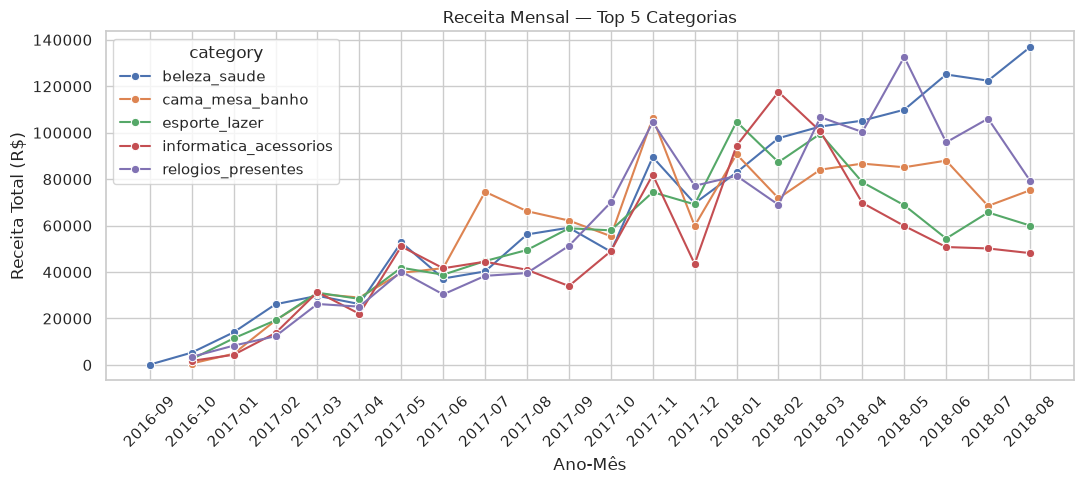

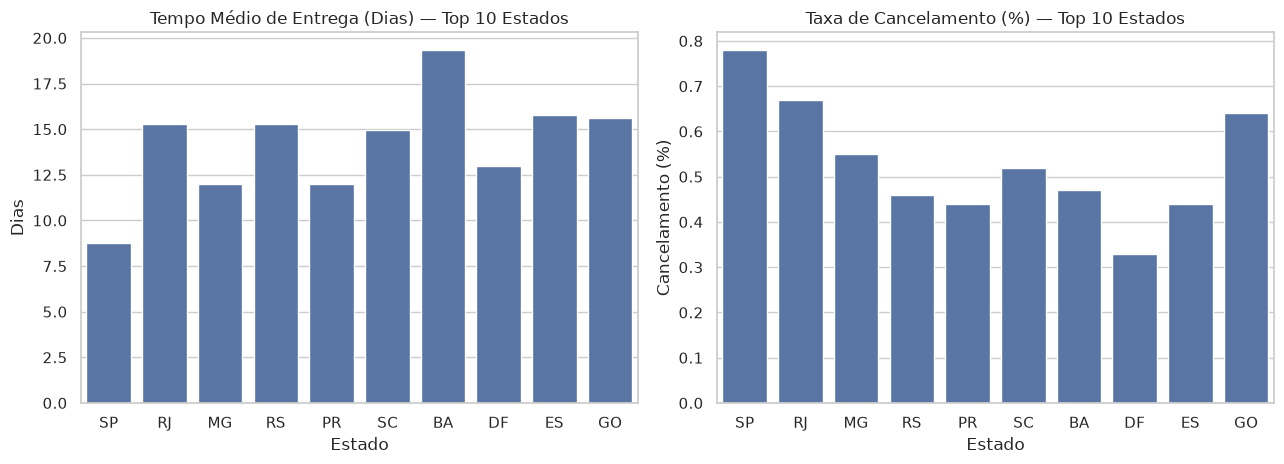

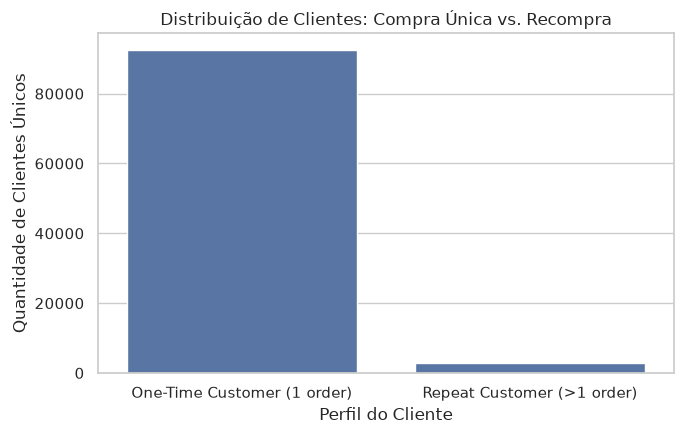

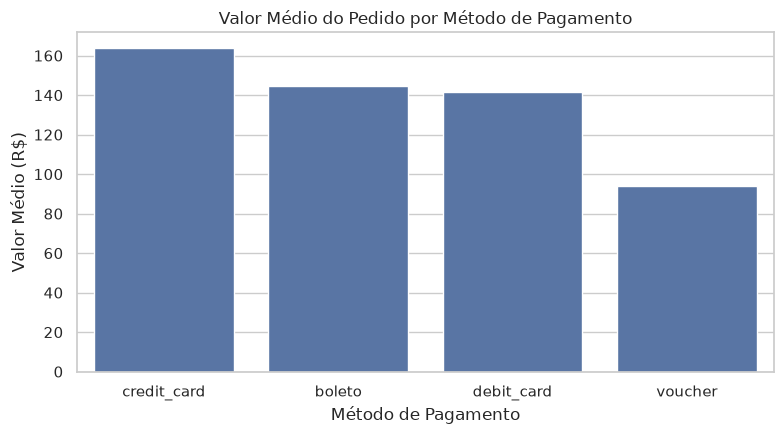

In [2]:
# 1. Receita mensal e top categorias
df_monthly_cat = pd.read_sql_query("""
    SELECT
        strftime('%Y-%m', o.order_purchase_timestamp) AS year_month,
        COALESCE(ct.product_category_name, p.product_category_name, 'unknown') AS category,
        SUM(oi.price + oi.freight_value) AS total_revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN products p ON oi.product_id = p.product_id
    LEFT JOIN category_translation ct ON p.product_category_name = ct.product_category_name
    WHERE o.order_status != 'canceled'
    GROUP BY year_month, category
""", conn)

top_cats = (
    df_monthly_cat.groupby("category")["total_revenue"]
    .sum()
    .nlargest(5)
    .index
)

monthly_trend = (
    df_monthly_cat[df_monthly_cat["category"].isin(top_cats)]
    .groupby(["year_month", "category"], as_index=False)["total_revenue"]
    .sum()
    .sort_values("year_month")
)

plt.figure(figsize=(11, 5))
sns.lineplot(data=monthly_trend, x="year_month", y="total_revenue", hue="category", marker="o")
plt.title("Receita Mensal — Top 5 Categorias")
plt.xlabel("Ano-Mês")
plt.ylabel("Receita Total (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "01_monthly_revenue_top_categories.png", dpi=300)
plt.show()

# 2. Tempo médio de entrega e taxa de cancelamento por estado (Top 10 por volume)
df_state = pd.read_sql_query("""
    SELECT
        c.customer_state,
        COUNT(*) AS total_orders,
        SUM(CASE WHEN o.order_status = 'canceled' THEN 1 ELSE 0 END) AS canceled_orders,
        ROUND(100.0 * SUM(CASE WHEN o.order_status = 'canceled' THEN 1 ELSE 0 END) / COUNT(*), 2) AS cancel_rate_pct,
        ROUND(AVG(
            CASE
                WHEN o.order_status = 'delivered'
                 AND o.order_delivered_customer_date IS NOT NULL
                 AND o.order_purchase_timestamp IS NOT NULL
                THEN (julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp))
            END
        ), 2) AS avg_delivery_days
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    GROUP BY c.customer_state
    ORDER BY total_orders DESC
    LIMIT 10
""", conn)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(data=df_state, x="customer_state", y="avg_delivery_days", ax=axes[0])
axes[0].set_title("Tempo Médio de Entrega (Dias) — Top 10 Estados")
axes[0].set_xlabel("Estado")
axes[0].set_ylabel("Dias")

sns.barplot(data=df_state, x="customer_state", y="cancel_rate_pct", ax=axes[1])
axes[1].set_title("Taxa de Cancelamento (%) — Top 10 Estados")
axes[1].set_xlabel("Estado")
axes[1].set_ylabel("Cancelamento (%)")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "02_delivery_cancel_by_state.png", dpi=300)
plt.show()

# 3. Retenção de clientes (compra única vs. recompra)
df_retention = pd.read_sql_query("""
    WITH customer_orders AS (
        SELECT
            c.customer_unique_id,
            COUNT(DISTINCT o.order_id) AS orders_count
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status != 'canceled'
        GROUP BY c.customer_unique_id
    )
    SELECT
        CASE WHEN orders_count > 1 THEN 'Repeat Customer (>1 order)' ELSE 'One-Time Customer (1 order)' END AS customer_type,
        COUNT(*) AS customers_count
    FROM customer_orders
    GROUP BY customer_type
""", conn)

plt.figure(figsize=(7, 4.5))
sns.barplot(data=df_retention, x="customer_type", y="customers_count")
plt.title("Distribuição de Clientes: Compra Única vs. Recompra")
plt.xlabel("Perfil do Cliente")
plt.ylabel("Quantidade de Clientes Únicos")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "03_customer_retention.png", dpi=300)
plt.show()

# 4. Valor médio por método de pagamento
df_payment = pd.read_sql_query("""
    WITH order_payment_totals AS (
        SELECT
            op.payment_type,
            op.order_id,
            SUM(op.payment_value) AS order_payment_total
        FROM order_payments op
        JOIN orders o ON op.order_id = o.order_id
        WHERE o.order_status != 'canceled'
        GROUP BY op.payment_type, op.order_id
    )
    SELECT
        payment_type,
        COUNT(*) AS orders_count,
        ROUND(SUM(order_payment_total), 2) AS total_paid_value,
        ROUND(AVG(order_payment_total), 2) AS avg_order_value
    FROM order_payment_totals
    GROUP BY payment_type
    ORDER BY avg_order_value DESC
""", conn)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=df_payment, x="payment_type", y="avg_order_value")
plt.title("Valor Médio do Pedido por Método de Pagamento")
plt.xlabel("Método de Pagamento")
plt.ylabel("Valor Médio (R$)")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "04_payment_avg_order_value.png", dpi=300)
plt.show()


In [1]:
import sqlite3
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = BASE_DIR / "olist.db"
IMAGES_DIR = BASE_DIR / "images"
IMAGES_DIR.mkdir(exist_ok=True)

conn = sqlite3.connect(DB_PATH)

orders = pd.read_sql_query("SELECT * FROM orders", conn)
for col in [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

orders["delivery_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivered_days = orders.loc[orders["order_status"] == "delivered", "delivery_days"].dropna()
print("Tempo de entrega (dias) — Pedidos entregues:")
print(f"  Média:         {delivered_days.mean():.2f}")
print(f"  Mediana:       {delivered_days.median():.2f}")
print(f"  Desvio padrão: {delivered_days.std():.2f}")

payments = pd.read_sql_query("SELECT * FROM order_payments", conn)
order_totals = payments.groupby("order_id", as_index=False)["payment_value"].sum()
print("\nValor total por pedido (R$):")
print(f"  Média:         {order_totals['payment_value'].mean():.2f}")
print(f"  Mediana:       {order_totals['payment_value'].median():.2f}")
print(f"  Desvio padrão: {order_totals['payment_value'].std():.2f}")


Matplotlib is building the font cache; this may take a moment.


Tempo de entrega (dias) — Pedidos entregues:
  Média:         12.56
  Mediana:       10.22
  Desvio padrão: 9.55

Valor total por pedido (R$):
  Média:         160.99
  Mediana:       105.29
  Desvio padrão: 221.95
